In [2]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 5.949 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [6]:
%mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.671 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ certifi             2026.10.23  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.27.1      pyh5ded981_0         conda-forge
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-learn        1.9.0       np23py313hb9816c2_0  emscripten-forge-4x
+ setupto

In [8]:
# Importing libraries and loading the dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

GSV_BENCH_REF = "VDR-0712"
print("Bench reference: VDR-0712")

df = pd.read_csv("C_feeder_load.csv")

print(df.head())
print(df["split"].value_counts())

Bench reference: VDR-0712
   temp_max_C  peak_load_MW  split
0        14.9         890.9  train
1        21.3         876.3  train
2        33.8        1072.0  train
3        16.8         917.4  train
4        34.1        1096.7  train
split
val              300
train             60
test_heatwave     20
Name: count, dtype: int64


In [9]:
# Separate training, validation and heatwave data

train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
heat_df = df[df["split"] == "test_heatwave"]

X_train = train_df[["temp_max_C"]]
y_train = train_df["peak_load_MW"]

X_val = val_df[["temp_max_C"]]
y_val = val_df["peak_load_MW"]

# Do not inspect or evaluate heatwave rows until C3 

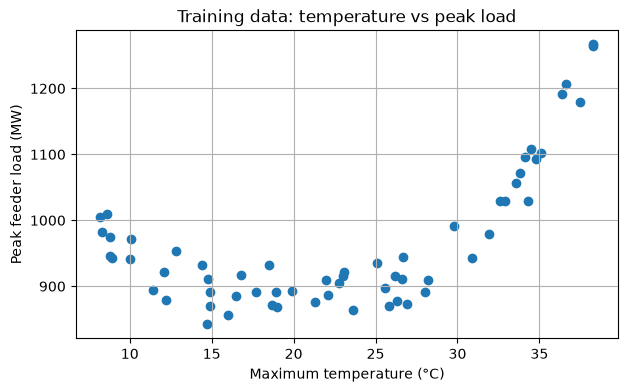

In [10]:
# Plotting the training data first

plt.figure(figsize=(7, 4))
plt.scatter(X_train["temp_max_C"], y_train)
plt.xlabel("Maximum temperature (°C)")
plt.ylabel("Peak feeder load (MW)")
plt.title("Training data: temperature vs peak load")
plt.grid(True)
plt.show()

In [15]:
# C1 - Polynomial regression

degrees = [1, 2, 3, 4, 6, 10, 15]

results = []
models = {}

for d in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    models[d] = model
    results.append({
        "Degree": d,
        "Train RMSE (MW)": train_rmse,
        "Validation RMSE (MW)": val_rmse
    })

c1_results = pd.DataFrame(results)

# Selecting the degree with the lowest validation RMSE
d_star = int(
    c1_results.loc[
        c1_results["Validation RMSE (MW)"].idxmin(),
        "Degree"
    ]
)

print("Best polynomial degree (d_star):", d_star)

display(c1_results.round(1))

Best polynomial degree (d_star): 10


,Degree,Train RMSE (MW),Validation RMSE (MW)
0,1,80.5,94.5
1,2,30.2,41.2
2,3,27.2,33.2
3,4,25.7,29.6
4,6,24.7,32.3
5,10,24.5,28.8
6,15,24.6,29.2


In [12]:
# C2 - Learning Curves

sample_sizes = [10, 15, 20, 30, 45, 60]
learning_results = []

for d in [1, 10]:
    for m in sample_sizes:
        model = make_pipeline(
            PolynomialFeatures(degree=d, include_bias=False),
            StandardScaler(),
            LinearRegression()
        )

        # First m training rows, preserving file order
        X_sub = X_train.iloc[:m]
        y_sub = y_train.iloc[:m]

        model.fit(X_sub, y_sub)

        train_rmse = np.sqrt(
            mean_squared_error(y_sub, model.predict(X_sub))
        )
        val_rmse = np.sqrt(
            mean_squared_error(y_val, model.predict(X_val))
        )

        learning_results.append({
            "Degree": d,
            "m": m,
            "Train RMSE (MW)": train_rmse,
            "Validation RMSE (MW)": val_rmse
        })

c2_results = pd.DataFrame(learning_results)
display(c2_results.round(1))

,Degree,m,Train RMSE (MW),Validation RMSE (MW)
0,1,10,36.0,92.1
1,1,15,49.8,92.7
2,1,20,54.1,95.6
3,1,30,75.9,93.0
4,1,45,81.0,92.9
5,1,60,80.5,94.5
6,10,10,13.1,69.7
7,10,15,12.8,135.1
8,10,20,22.0,90.6
9,10,30,23.3,67.7


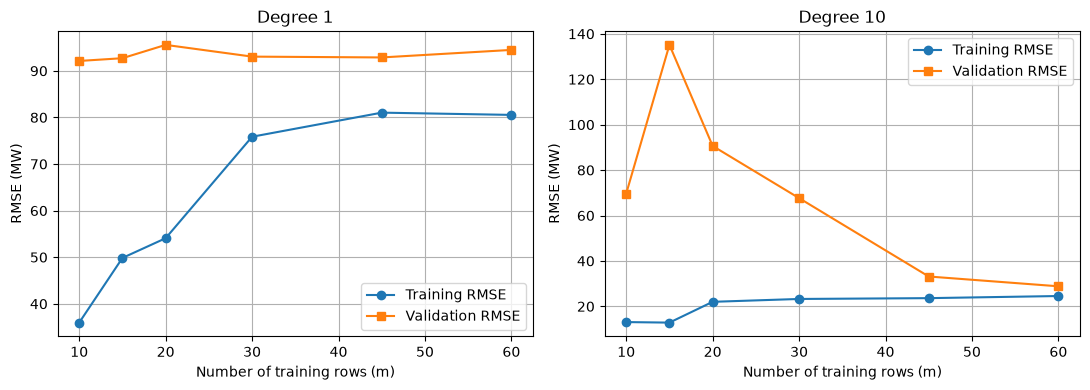

In [13]:
# Plotting and saving the learning curves 

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, d in zip(axes, [1, 10]):
    subset = c2_results[c2_results["Degree"] == d]

    ax.plot(subset["m"], subset["Train RMSE (MW)"],
            marker="o", label="Training RMSE")
    ax.plot(subset["m"], subset["Validation RMSE (MW)"],
            marker="s", label="Validation RMSE")

    ax.set_title(f"Degree {d}")
    ax.set_xlabel("Number of training rows (m)")
    ax.set_ylabel("RMSE (MW)")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.savefig("C2_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
# C3: Evaluate models on the heatwave test set

# Select heatwave test data
heat_df = df[df["split"] == "test_heatwave"]

X_heat = heat_df[["temp_max_C"]]
y_heat = heat_df["peak_load_MW"]

# Models to evaluate
models_to_test = {
    "Degree 3": models[3],
    f"Best degree ({d_star})": models[d_star],
    "Degree 15": models[15]
}

# Calculate heatwave RMSE
c3_results = []

for model_name, model in models_to_test.items():
    y_pred = model.predict(X_heat)

    heatwave_rmse = np.sqrt(
        mean_squared_error(y_heat, y_pred)
    )

    c3_results.append({
        "Model": model_name,
        "Heatwave RMSE (MW)": heatwave_rmse
    })

# Display results
c3_results = pd.DataFrame(c3_results)

display(c3_results.round(2))

,Model,Heatwave RMSE (MW)
0,Degree 3,102.48
1,Best degree (10),4182.89
2,Degree 15,1081.30


Physics-informed model
Training RMSE: 24.69 MW
Heatwave RMSE: 77.60 MW

Polynomial model (degree 10)
Heatwave RMSE: 4182.89 MW


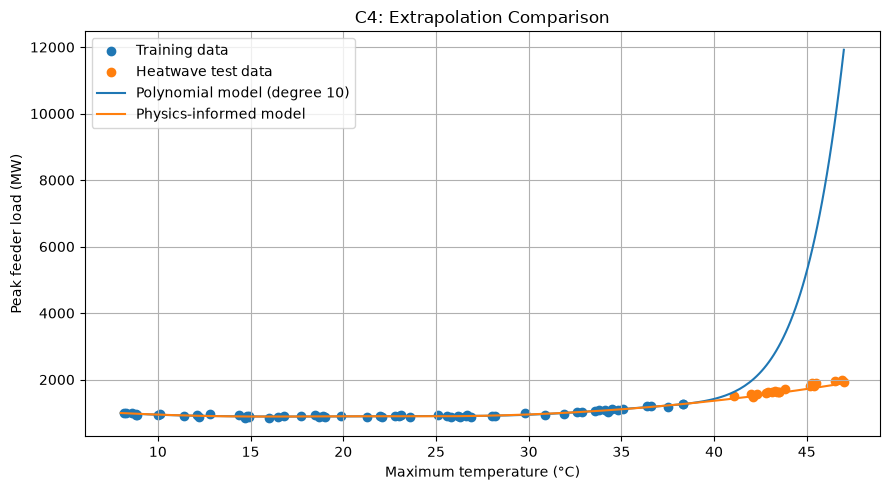

In [18]:
#C4 - Physics informed features

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Separate the datasets
train_df = df[df["split"] == "train"]
heat_df = df[df["split"] == "test_heatwave"]

X_train = train_df[["temp_max_C"]]
y_train = train_df["peak_load_MW"]

X_heat = heat_df[["temp_max_C"]]
y_heat = heat_df["peak_load_MW"]


# Create physics-informed features
def make_physics_features(X):
    T = np.asarray(X).reshape(-1)

    h = np.maximum(18 - T, 0)
    c = np.maximum(T - 24, 0)

    return pd.DataFrame({
        "h": h,
        "c": c,
        "h2": h**2,
        "c2": c**2
    })


# Transform the input data
X_train_phys = make_physics_features(X_train)
X_heat_phys = make_physics_features(X_heat)


# Build and train the physics-informed model
physics_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

physics_model.fit(X_train_phys, y_train)


# TODO 1: Predict training-set loads
y_train_phys_pred = physics_model.predict(X_train_phys)

# TODO 2: Calculate training RMSE
train_rmse_phys = np.sqrt(
    mean_squared_error(y_train, y_train_phys_pred)
)

# TODO 3: Predict heatwave loads
y_heat_phys_pred = physics_model.predict(X_heat_phys)

# TODO 4: Calculate heatwave RMSE
heat_rmse_phys = np.sqrt(
    mean_squared_error(y_heat, y_heat_phys_pred)
)

# TODO 5: Compare with the selected polynomial model
y_heat_poly_pred = models[d_star].predict(X_heat)

heat_rmse_poly = np.sqrt(
    mean_squared_error(y_heat, y_heat_poly_pred)
)

print("Physics-informed model")
print(f"Training RMSE: {train_rmse_phys:.2f} MW")
print(f"Heatwave RMSE: {heat_rmse_phys:.2f} MW")

print(f"\nPolynomial model (degree {d_star})")
print(f"Heatwave RMSE: {heat_rmse_poly:.2f} MW")


# Create temperature range for extrapolation
T_plot = np.linspace(8, 47, 300).reshape(-1, 1)

X_plot = pd.DataFrame(
    T_plot,
    columns=["temp_max_C"]
)

# Polynomial model predictions
y_poly = models[d_star].predict(X_plot)

# Physics-informed model predictions
X_plot_phys = make_physics_features(X_plot)
y_phys = physics_model.predict(X_plot_phys)


# Plot the results
plt.figure(figsize=(9, 5))

plt.scatter(
    X_train["temp_max_C"],
    y_train,
    label="Training data"
)

plt.scatter(
    X_heat["temp_max_C"],
    y_heat,
    label="Heatwave test data"
)

plt.plot(
    X_plot["temp_max_C"],
    y_poly,
    label=f"Polynomial model (degree {d_star})"
)

plt.plot(
    X_plot["temp_max_C"],
    y_phys,
    label="Physics-informed model"
)

plt.xlabel("Maximum temperature (°C)")
plt.ylabel("Peak feeder load (MW)")
plt.title("C4: Extrapolation Comparison")
plt.grid(True)
plt.legend()
plt.tight_layout()

# Save the figure
plt.savefig(
    "C4_extrapolation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()